# P5 商品聚类

- 样本：`scope.parquet` 中 `in_scope=True` 的 40,259 件商品，一行一个商品
- 特征：评论数、评论长度、verified 比例、also_buy/also_view 长度、卖点数、描述长度、类目深度、排名数、图片数、类目频数等 13 个；不使用评分
- 价格缺失 83.44%，不进入聚类特征，只在簇画像里事后统计
- 标准化后用 KMeans，k=2–10 以轮廓系数选，且每个簇不少于样本的 2%
- 50 次 bootstrap 重采样计算 ARI
- 复现：`python src/cluster.py --force`


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path('..').resolve()
TABLES = ROOT / 'results' / 'tables'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC']
plt.rcParams['axes.unicode_minus'] = False

summary = json.loads((TABLES / 'cluster_summary.json').read_text(encoding='utf-8'))
print('商品数', summary['input']['n_products'])
print('聚类特征', len(summary['input']['feature_names']), '个')
print('选定 k', summary['k_selection']['chosen_k'])
print('簇规模', summary['cluster_sizes'])
print('稳定性', summary['stability'])
print('断言', summary['assertions'])

商品数 40259
聚类特征 13 个
选定 k 4
簇规模 [7797, 11877, 18430, 2155]
稳定性 {'n_bootstrap': 50, 'ari_mean': 0.9849, 'ari_ci95': [0.9296, 0.9976], 'min_required': 0.6, 'bootstrap_fraction': 0.8}
断言 {'k_ge_2': True, 'each_cluster_nonempty': True, 'ari_ge_0_6': True, 'scope_only': True, 'features_standardized': True}


,k,inertia,silhouette
0,2,432774.55,0.1662
1,3,373732.68,0.1951
2,4,334281.11,0.2090
3,5,295383.73,0.2013
4,6,280529.79,0.1894
5,7,265513.07,0.2082
6,8,254801.68,0.1803
7,9,242512.42,0.1675
8,10,234759.01,0.1552


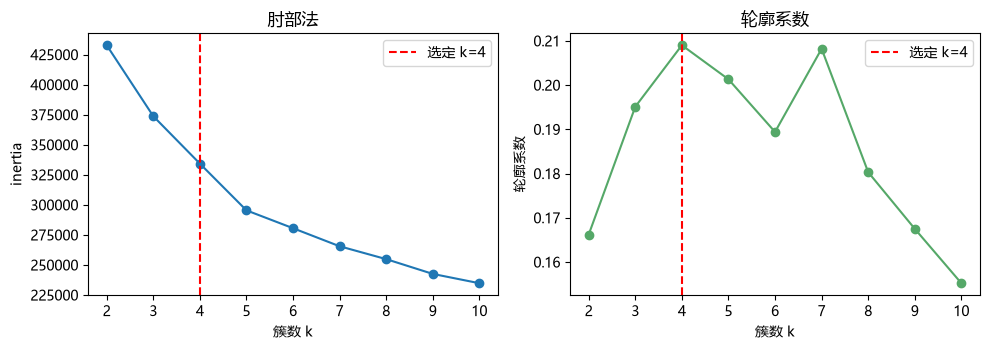

In [2]:
selection = summary['k_selection']
table = pd.DataFrame({'k': selection['k'], 'inertia': selection['inertia'], 'silhouette': selection['silhouette']})
display(table)

chosen = selection['chosen_k']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(table['k'], table['inertia'], marker='o')
axes[0].axvline(chosen, color='red', linestyle='--', label=f'选定 k={chosen}')
axes[0].set_xlabel('簇数 k')
axes[0].set_ylabel('inertia')
axes[0].set_title('肘部法')
axes[0].legend()
axes[1].plot(table['k'], table['silhouette'], marker='o', color='#55a868')
axes[1].axvline(chosen, color='red', linestyle='--', label=f'选定 k={chosen}')
axes[1].set_xlabel('簇数 k')
axes[1].set_ylabel('轮廓系数')
axes[1].set_title('轮廓系数')
axes[1].legend()
plt.tight_layout()
plt.show()

In [3]:
profiles = pd.read_csv(TABLES / 'cluster_profiles.csv')
columns = ['cluster', 'name', 'size', 'share', 'mean_overall', 'mean_n_reviews', 'mean_mean_review_len', 'mean_also_buy_len', 'mean_description_len']
display(profiles[columns].round(3))
display(profiles[['name', 'top_titles']])

,cluster,name,size,share,mean_overall,mean_n_reviews,mean_mean_review_len,mean_also_buy_len,mean_description_len
0,0,中等热度,7797,0.194,3.641,25.359,427.647,9.243,1127.056
1,1,高热度·共购密集,11877,0.295,4.011,94.464,503.211,47.520,1703.844
2,2,长尾·共购稀疏,18430,0.458,3.747,5.946,414.525,2.546,705.188
3,3,中等热度·Software,2155,0.054,3.671,12.453,398.555,4.993,650.011


,name,top_titles
0,中等热度,Battlefield 3 [Download]; Batman: Arkham Knigh...
1,高热度·共购密集,Diablo III; StarCraft II: Wings of Liberty; Wi...
2,长尾·共购稀疏,Plantronics Gamecom X10 - Xbox 360; Far Cry 4 ...
3,中等热度·Software,Wii Sports; Battlefield 1 - PlayStation 4; Bat...


bootstrap 50 次
count    50.0000
mean      0.9849
std       0.0614
min       0.5671
25%       0.9939
50%       0.9954
75%       0.9965
max       0.9982


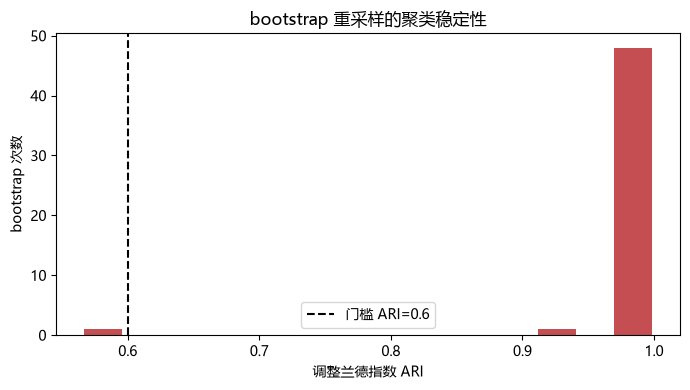

In [4]:
stability = pd.read_csv(TABLES / 'cluster_stability.csv')
print('bootstrap', len(stability), '次')
print(stability['ari'].describe().round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(stability['ari'], bins=15, color='#c44e52')
ax.axvline(0.6, color='black', linestyle='--', label='门槛 ARI=0.6')
ax.set_xlabel('调整兰德指数 ARI')
ax.set_ylabel('bootstrap 次数')
ax.set_title('bootstrap 重采样的聚类稳定性')
ax.legend()
plt.tight_layout()
plt.show()

## 簇解释

1. **高热度·共购密集**（11,877 件，29.5%）：平均 94.5 条评论、`also_buy` 47.5 个、描述 1,703 字符、平均评分 4.01，是主力大作与合集，评论与推荐位都最丰富。
2. **中等热度**（7,797 件，19.4%）：25.4 条评论、`also_buy` 9.2 个、描述 1,127 字符，代表商品多为 `[Download]`、`[Digital Code]` 形态，是数字版中坚。
3. **长尾·共购稀疏**（18,430 件，45.8%）：5.9 条评论、`also_buy` 2.5 个、描述 705 字符，占近一半，是长尾冷门商品。
4. **中等热度·Software**（2,155 件，5.4%）：主品类为 Software，12.5 条评论，排名数与商品图片数明显偏少，是品类边界保留下来的软件类商品。

稳定性：50 次 bootstrap 的 ARI 均值 0.9849，95% 区间 [0.9296, 0.9976]，高于 0.6 的门槛；说明在重采样下簇结构基本可复现。

## 已知限制

- 轮廓系数最高只有 0.209，说明商品特征空间里没有强分离的簇，分群更适合当“运营分层”而不是“天然类别”。
- 价格缺失 83.44%，若放进距离会让聚类退化成“有没有标价”两群，因此只做事后画像。
- 评论数、评论长度等聚合特征受热度影响，聚类结果部分等价于“热门/长尾”分层。
- KMeans 假设簇是球形且尺度相近；缩尾到 1%–99% 分位，极端商品被压平。
- ARI 高只说明重采样可复现，不代表簇的语义一定成立。
